# Regression Validation  


**Our three questions:**

(1) What relationship do we estimate?

(2) Can we trust our statistical conclusions?

(3) How well do we predict new salaries?

**Lesson map**
1. Data and regression → 2. Relationship and functional form → 3. Residual assumptions → 4. Unusual observations → 5. Prediction and validation → 6. Final evaluation. Optional extensions appear **after** the conclusion.

## Part A — Understand the data and fit a model
### 1. Import and clean data
**Purpose:** Check column names, missing entries and valid Age–Salary pairs. A regression cannot use rows with missing Age or Salary.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

file_path = 'https://raw.githubusercontent.com/tec03/Datasets/main/datasets/reg_data.csv'

df = pd.read_csv(file_path)
print('Original dataset shape:', df.shape)
print('Columns:', list(df.columns))
print('Missing values per column:')
print(df.isna().sum().to_string())

Original dataset shape: (150, 8)
Columns: ['Gender', 'Age', 'Place', 'Weight', 'Company', 'Education', 'JoinYear', 'Salary']
Missing values per column:
Gender       14
Age           9
Place        14
Weight       15
Company      13
Education    15
JoinYear     15
Salary       15


In [2]:
# Normalize the two column names we need
names = {str(c).strip().casefold(): c for c in df.columns}
if not {'age', 'salary'}.issubset(names):
    raise ValueError('The file must contain Age and Salary columns.')
df = df.rename(columns={names['age']: 'Age',
                        names['salary']: 'Salary'
                        })
print('Age and Salary columns found.')

Age and Salary columns found.


In [3]:
# Keep complete observations for the Age–Salary regression
# Keep df unchanged: later sections may examine other recorded predictors.
data = df[['Age', 'Salary']].copy()
data[['Age', 'Salary']] = data[['Age', 'Salary']].apply(pd.to_numeric, errors='coerce')
data = data.dropna(subset=['Age', 'Salary'])
print(f'Using {len(data)} complete rows out of {len(df)} original rows.')

Using 128 complete rows out of 150 original rows.


In [4]:
display(data[['Age', 'Salary']].describe().T)
print('Complete observations:',len(data))

,count,mean,std,min,25%,50%,75%,max
Age,128.0,40.492188,11.795499,22.0,29.75,41.0,52.25,59.0
Salary,128.0,60553.906250,7021.229000,44286.0,55487.00,60798.5,65805.25,74862.0


Complete observations: 128


### 2. Fit the Age–Salary regression
**Purpose:** Estimate the average salary difference associated with one additional year of age.

**Observe:** Age coefficient (direction and size), its confidence interval/p-value, and R². **Do not interpret association as causation.**

In [5]:
X = sm.add_constant(data[['Age']],
                    has_constant='add')
y = data['Salary']

model = sm.OLS(y, X).fit()

print('Regression summary:')
print(model.summary())

print('\nCompare with published results (do not force a match):')
print(f"n={int(model.nobs)}, b1={model.params['Age']:.4f}, SE={model.bse['Age']:.3f}, R²={model.rsquared:.3f}")

Regression summary:
                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.636
Model:                            OLS   Adj. R-squared:                  0.634
Method:                 Least Squares   F-statistic:                     220.6
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           1.82e-29
Time:                        03:25:41   Log-Likelihood:                -1250.0
No. Observations:                 128   AIC:                             2504.
Df Residuals:                     126   BIC:                             2510.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       4.132e+04   1348.047

In [6]:
new = pd.DataFrame({'Age':[25, 40, 55]})
new['Predicted Salary'] = model.predict(sm.add_constant(new,has_constant='add'))
display(new.round(2))

,Age,Predicted Salary
0,25,53196.93
1,40,60320.17
2,55,67443.42


## Part B — Does the *shape* of the model make sense?
### 3. Visual check: scatter, straight line, and LOWESS
**Purpose:** Compare actual salaries to a straight line and a flexible smooth trend.

**Good:** Flexible trend roughly tracks the straight line. **Investigate:** systematic bending, distinct groups, or unexplained extremes.

In [7]:
plt.style.use('ggplot')

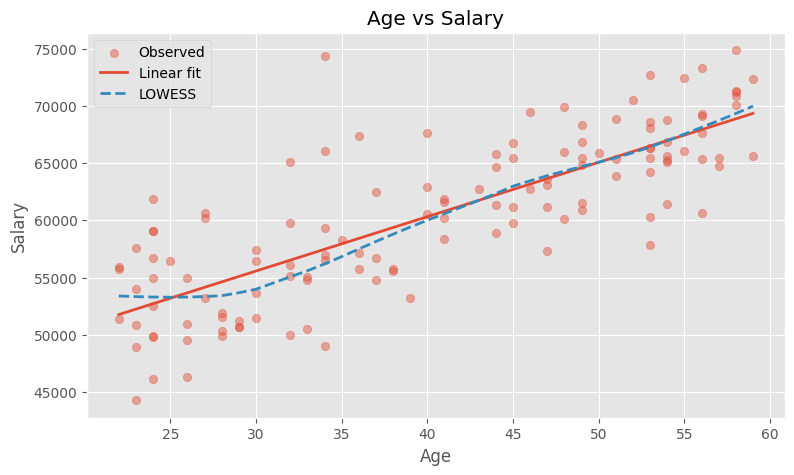

In [8]:
age_grid = np.linspace(data.Age.min(), data.Age.max(), 200)

fit_line = model.params['const'] + model.params['Age']*age_grid

smooth = sm.nonparametric.lowess(data.Salary,
                                 data.Age,
                                 frac=0.4,
                                 return_sorted=True)

plt.figure(figsize=(9,5))
plt.scatter(data.Age,
            data.Salary,
            alpha=0.45,
            label='Observed'
            )

plt.plot(age_grid,
         fit_line,
         label='Linear fit',
         linewidth=2
         )

plt.plot(smooth[:,0],
         smooth[:,1],
         '--',label='LOWESS',linewidth=2)

plt.xlabel('Age');plt.ylabel('Salary');plt.title('Age vs Salary');plt.legend();plt.show()

### 3.1 — Interpretation: Age vs. Salary

**Purpose:** Check whether Age and Salary have a linear relationship.

**Understanding the graph:**
- **Red dots:** Actual salary observations.
- **Solid red line:** Fitted linear regression.
- **Blue dashed line (LOWESS):** Smoothed relationship that helps identify nonlinear patterns.

**What should we look for?**

- **Good:** The LOWESS curve stays close to the regression line, without strong systematic curvature.
- **Potential problem:** The LOWESS curve bends substantially away from the regression line, suggesting a nonlinear relationship.

**Our observations:**
- Salary generally increases as Age increases.
- The LOWESS curve remains reasonably close to the linear regression line.
- Slight deviations appear at younger ages, but no strong curvature is visible.
- Individual salaries vary around the fitted line.

**Conclusion:**

The graph suggests a positive, approximately linear relationship between Age and Salary. Therefore, a linear regression appears reasonable as an initial model.

**Remember:** Visual inspection alone cannot confirm that the linear model is appropriate. We should also examine the quadratic Age term, Ramsey RESET, and lack-of-fit test.

### 4. Formal checks: quadratic Age, Ramsey RESET, lack-of-fit
**Purpose:** Ask if the linear mean relationship is missing curvature.

**Quadratic:** Add both Age and Age² (not Age² alone). **RESET:** General warning of specification problems. **Pure-error lack-of-fit:** Only possible with repeated ages and suitable independent, constant-variance errors.

**For these tests:** p < .05 gives evidence against the simpler linear specification; p ≥ .05 **does not prove** it is correct.

In [9]:
from statsmodels.stats.diagnostic import linear_reset
from statsmodels.stats.anova import anova_lm

reset=linear_reset(model,
                   power=2,
                   use_f=True
                   )

print(f'Ramsey RESET F={float(reset.fvalue):.3f}, p={float(reset.pvalue):.5g}')

quadratic_X = sm.add_constant(pd.DataFrame({'Age':data['Age'],
                                            'Age_squared':data['Age']**2},index=data.index)
)

quadratic=sm.OLS(y,quadratic_X).fit()
print('\nNested comparison: linear vs quadratic')

display(anova_lm(model,quadratic))
print('Adjusted R² (linear, quadratic):',round(model.rsquared_adj,3),round(quadratic.rsquared_adj,3))

print('Quadratic Age² p-value:',quadratic.pvalues['Age_squared'])

Ramsey RESET F=0.131, p=0.71798

Nested comparison: linear vs quadratic


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,126.0,2.275972e+09,0.0,NaN,NaN,NaN
1,125.0,2.273589e+09,1.0,2.383282e+06,0.131031,0.717977


Adjusted R² (linear, quadratic): 0.634 0.631
Quadratic Age² p-value: 0.7179768171371288


### 4.1 — Quadratic Model and Ramsey RESET

**Purpose:** Check whether a straight-line relationship between Age and Salary is sufficient or whether a curved relationship is needed.

**What should we look for?**

- **p < 0.05:** Evidence that the linear model may be missing nonlinear structure.
- **p ≥ 0.05:** No statistically significant evidence of the tested misspecification.

**Our results:**

| Test | p-value | Interpretation |
|---|---:|---|
| Ramsey RESET | 0.71798 | No significant evidence of misspecification |
| Quadratic Age² | 0.71798 | No evidence that Age² improves the model |
| Adjusted R² (linear) | 0.634 | Slightly better |
| Adjusted R² (quadratic) | 0.631 | Slightly lower |

**Conclusion:** The quadratic term does not significantly improve the model, and Ramsey RESET does not detect a functional-form problem. Therefore, the simpler linear Age–Salary model is preferred based on these results.

**Remember:** A nonsignificant RESET test does not prove that all relevant variables are included or that the model is perfectly specified.

Pure-error lack-of-fit: F=1.034; p=0.4366


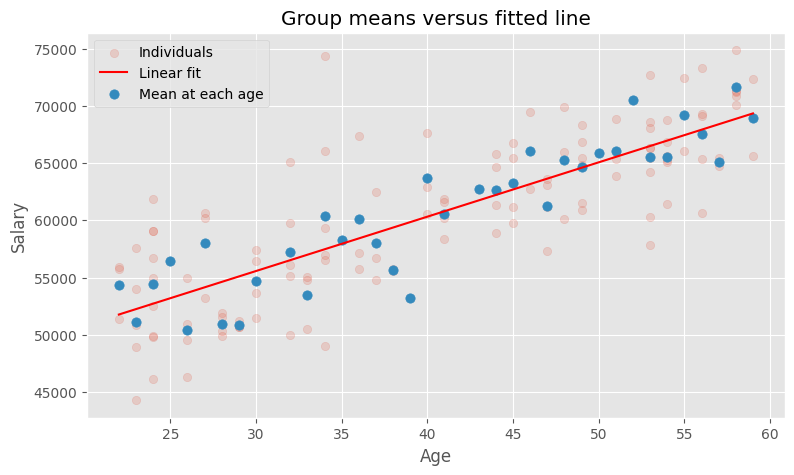

In [10]:
groups = data.groupby('Age')['Salary']

n,g,p = len(data),groups.ngroups,len(model.params)

pure_error = groups.apply(lambda s: ((s-s.mean())**2).sum()).sum()

if n>g>p and pure_error>0:
    sse = float(np.sum(model.resid**2))
    F = (max(0,sse-pure_error)/(g-p))/(pure_error/(n-g))
    lof_p = stats.f.sf(F,g-p,n-g)
    print(f'Pure-error lack-of-fit: F={F:.3f}; p={lof_p:.4f}')
else:
    lof_p = np.nan
    print('Pure-error lack-of-fit test unavailable: insufficient replicates.')
means=groups.mean()
plt.figure(figsize=(9,5));plt.scatter(data.Age,data.Salary,alpha=.18,label='Individuals')
plt.plot(age_grid,fit_line,label='Linear fit',color='red')
plt.scatter(means.index,means.values,s=45,label='Mean at each age')
plt.xlabel('Age');plt.ylabel('Salary');plt.legend();plt.title('Group means versus fitted line');plt.show()

### 4.2 — Lack-of-Fit Test

**Purpose:** Check whether the fitted straight line adequately describes the average Salary at different ages.

**Understanding the graph:**

- **Light-blue dots:** Individual employee salaries.
- **Red line:** Predicted Salary from linear regression.
- **Orange dots:** Average Salary at each age.

**What is good?**

Orange dots appear on both sides of the red line without a clear systematic pattern.

**What is concerning?**

Orange dots form a curve or consistently deviate from the red line in a systematic way, suggesting the linear model may not fit adequately.

**Our observations:**

The average salaries generally follow the upward trend of the regression line. Although some deviations exist, there is no obvious systematic curvature.

**Statistical result:**

- F-statistic = 1.034
- p-value = 0.4366

Since **p > 0.05**, we do not reject the hypothesis of no lack of fit.

**Conclusion:** The graph and test do not indicate significant lack of fit. The linear Age–Salary relationship appears reasonable based on this diagnostic.

**Remember:** Passing the lack-of-fit test does not mean the model predicts every individual's salary accurately. The test also relies on assumptions such as independent observations and constant error variance.

## Part C — Do residuals behave as expected?
### 5. Residual patterns and constant variance
**Purpose:** Residual = actual − predicted salary. Inspect whether residuals form a pattern or spread out as salaries increase.

**Good:** Random points around zero, roughly even vertical spread. **Investigate:** curve (missed structure) or funnel (changing variance).

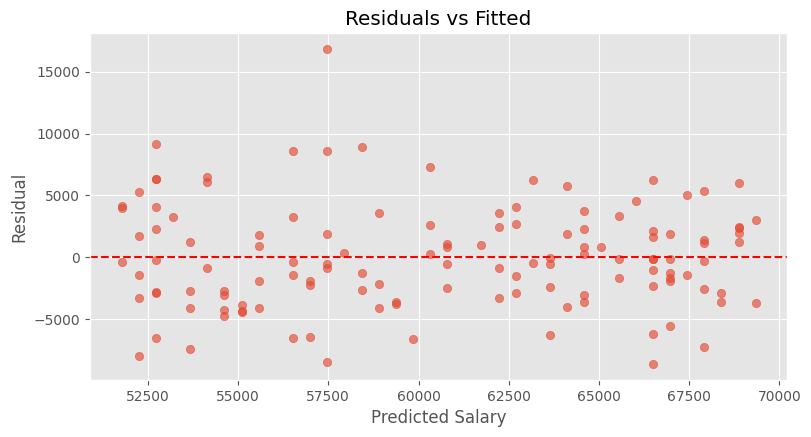

In [11]:
fitted=np.asarray(model.fittedvalues);
resid=np.asarray(model.resid)
plt.figure(figsize=(9,4.5))
plt.scatter(fitted,resid,alpha=.65)
plt.axhline(0,linestyle='--',color='red')
plt.xlabel('Predicted Salary');plt.ylabel('Residual');plt.title('Residuals vs Fitted');plt.show()

### 5.1 — Residuals vs. Fitted Values

**Purpose:** Check whether regression errors are randomly distributed around zero, with approximately constant variance.

**What should we look for?**

- **Good:** Random scatter around zero, with roughly equal vertical spread.
- **Potential problem:** A curved pattern suggests model misspecification.
- **Potential problem:** A funnel shape suggests heteroscedasticity (changing variance).
- **Outliers:** Points unusually far from zero require investigation.

**Our observations:**

- Residuals are scattered on both sides of zero.
- No obvious curved or funnel-shaped pattern is visible.
- The spread appears reasonably consistent across predicted salaries.
- One unusually large positive residual (around +17,000) stands out.

**Conclusion:**

The residual plot does not show strong visual evidence of nonlinearity or heteroscedasticity. However, the unusually large residual should be investigated.

**Remember:** A residual plot is a visual diagnostic, not a formal statistical test. Use Breusch–Pagan or White's test to supplement the constant-variance assessment.

### 6. Formal equal-variance tests and HC3 uncertainty
**Purpose:** BP and White test whether residual variance changes with explanatory variables.

**p < .05:** evidence of heteroscedasticity. **p ≥ .05:** insufficient evidence, not proof of constant variance.

**HC3:** Keeps OLS coefficients and fitted values, but recalculates standard errors, confidence intervals and p-values. It does **not** fix omitted variables or model form.

In [12]:
from statsmodels.stats.diagnostic import het_breuschpagan,het_white

bp=het_breuschpagan(model.resid, model.model.exog)
print(f'Breusch–Pagan LM p-value: {bp[1]:.5g}\n \t\t\t    F p-value: {bp[3]:.5g}')

white=het_white(model.resid,model.model.exog)
print(f'White test LM p-value: {white[1]:.5g}')

hc3=model.get_robustcov_results(cov_type='HC3')

compare=pd.DataFrame({'Coefficient':model.params.values,
                      'Conventional_SE':model.bse.values,
                      'HC3_SE':hc3.bse,
                      'Conventional_p':model.pvalues.values,
                      'HC3_p':hc3.pvalues},index=model.params.index)
display(compare.round(6))

Breusch–Pagan LM p-value: 0.069548
 			    F p-value: 0.070487
White test LM p-value: 0.17438


,Coefficient,Conventional_SE,HC3_SE,Conventional_p,HC3_p
const,41324.850176,1348.046519,1439.223421,0.0,0.0
Age,474.883114,31.972753,31.747815,0.0,0.0


### 6.1 — Constant Variance and HC3 Robust Standard Errors

**Purpose:** Check whether regression errors have constant variance (homoscedasticity) and whether our statistical conclusions remain reliable using HC3 robust standard errors.

**What should we look for?**

- **BP / White p < 0.05:** Evidence of heteroscedasticity (unequal error variance).
- **BP / White p ≥ 0.05:** No significant evidence of heteroscedasticity.
- **HC3:** Compare conventional and robust standard errors and p-values. Large differences may affect statistical conclusions.

**Our results:**

| Test | Result | Interpretation |
|---|---:|---|
| Breusch–Pagan | p = 0.0695 | No significant heteroscedasticity at 5% |
| White test | p = 0.1744 | No significant heteroscedasticity at 5% |
| Age coefficient | 474.88 | Unchanged with HC3 |
| Conventional SE (Age) | 31.97 | Original uncertainty estimate |
| HC3 SE (Age) | 31.75 | Very similar uncertainty estimate |

**Our observations:**

- Both tests have p-values above 0.05.
- HC3 barely changes the standard error for Age.
- Age remains statistically significant under both methods.

**Conclusion:**

There is no statistically significant evidence of heteroscedasticity at the 5% level. HC3 produces nearly identical standard errors for Age, so our conclusion about its statistical significance remains unchanged.

**Remember:** HC3 adjusts uncertainty estimates, not regression coefficients or predictions. It does not correct omitted-variable bias or an incorrect functional form.

### 7. Residual normality
**Purpose:** Normality supports classical exact small-sample inference; it is not required to calculate OLS coefficients.

**Look for:** A reasonably bell-shaped histogram and Q–Q points near the reference line. JB, Omnibus and AD test normality in different ways. **p < .05** indicates evidence of non-normality. Inspect large tail departures rather than treating one test as final.

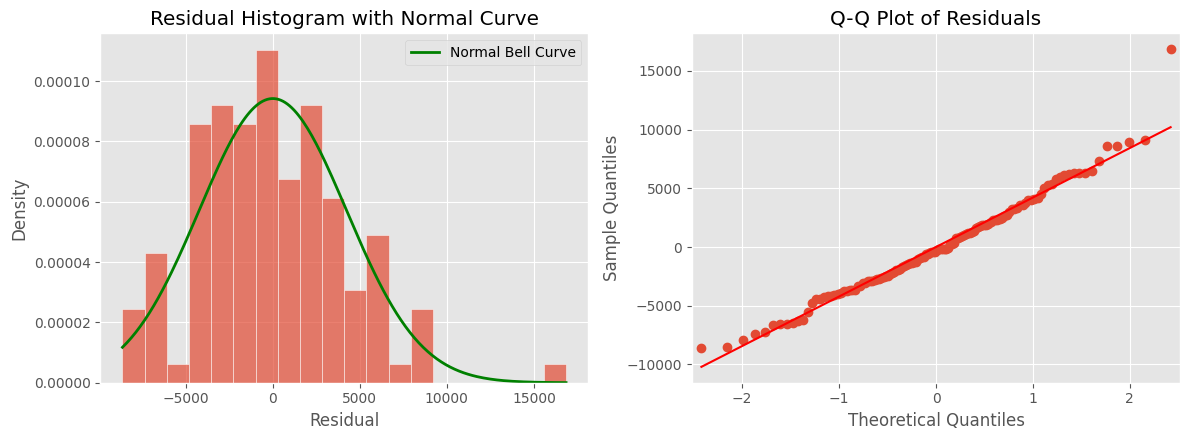

In [13]:
from statsmodels.stats.stattools import jarque_bera, omni_normtest
from scipy.stats import norm

residuals = model.resid

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Histogram with normal bell curve
axs[0].hist(residuals,
            bins=20,
            density=True,
            edgecolor='white',
            alpha=0.7)

mu = np.mean(residuals)
sigma = np.std(residuals, ddof=1)

x = np.linspace(min(residuals), max(residuals), 200)
axs[0].plot(x,
            norm.pdf(x, mu, sigma),
            color='green',
            linewidth=2,
            label='Normal Bell Curve')

axs[0].set(xlabel='Residual',
           ylabel='Density',
           title='Residual Histogram with Normal Curve')
axs[0].legend()

# 2. Q-Q plot
sm.qqplot(residuals,
          line='s',
          ax=axs[1]
          )
axs[1].set_title('Q-Q Plot of Residuals')

plt.tight_layout()
plt.show()



In [14]:
from statsmodels.stats.stattools import jarque_bera, omni_normtest
from statsmodels.stats.diagnostic import normal_ad
import pandas as pd

residuals = model.resid

# Normality tests
jb, jbp, skew, kurt = jarque_bera(residuals)
omni, op = omni_normtest(residuals)
ad_stat, ad_p = normal_ad(residuals)

# Combined results
results = pd.DataFrame({
    'Test': ['Jarque-Bera', 'Omnibus', 'Anderson-Darling'],
    'Statistic': [jb, omni, ad_stat],
    'p-value': [jbp, op, ad_p]
})

results['Conclusion (5%)'] = results['p-value'].apply(
    lambda p: 'Non-normal' if p < 0.05 else 'Do not reject normality'
)

display(results.round(5))

print(f"Skewness: {skew:.4f}")
print(f"Pearson Kurtosis: {kurt:.4f}")

,Test,Statistic,p-value,Conclusion (5%)
0,Jarque-Bera,11.90646,0.00260,Non-normal
1,Omnibus,10.69391,0.00476,Non-normal
2,Anderson-Darling,0.41973,0.32138,Do not reject normality


Skewness: 0.5585
Pearson Kurtosis: 3.9923


### 7.1 — Residual Normality: Interpretation

**Purpose:** Check whether regression errors are approximately normally distributed.

**What should we look for?**

- **Histogram:** Ideally, bars approximately follow the normal bell-shaped curve.
- **Q–Q plot:** Ideally, points approximately follow the straight reference line.
- **Normality tests:** p < 0.05 indicates evidence against normality; p ≥ 0.05 means insufficient evidence to reject normality.

**Our results:**

| Test | p-value | Interpretation |
|---|---:|---|
| Jarque–Bera | 0.00260 | Reject normality |
| Omnibus | 0.00476 | Reject normality |
| Anderson–Darling | 0.32138 | Do not reject normality |

**Our observations:**

- The histogram is approximately bell-shaped but slightly right-skewed.
- Most Q–Q points follow the straight line, except for deviations in the upper tail.
- One unusually large positive residual is visible.
- Skewness = 0.5585 and kurtosis = 3.9923, indicating moderate positive skewness and heavier tails than a normal distribution.

**Conclusion:**

Jarque–Bera and Omnibus indicate statistically significant departures from normality, while Anderson–Darling does not reject normality.

The residuals appear approximately normal in the center, but **normality is questionable, particularly in the upper tail**.

**Remember:** Non-normal residuals do not automatically invalidate OLS coefficients. Normality is mainly important for exact classical small-sample inference.

### 8. Error independence — only when row order matters
**Purpose:** For time-ordered data, check whether consecutive errors are related.

**Look for:** No runs or waves in residuals by time. DW near 2 is broadly consistent with weak first-order autocorrelation, **not proof** of independence. When employee rows have arbitrary order, this chart and DW cannot establish independence; evaluate sampling/clustering instead.

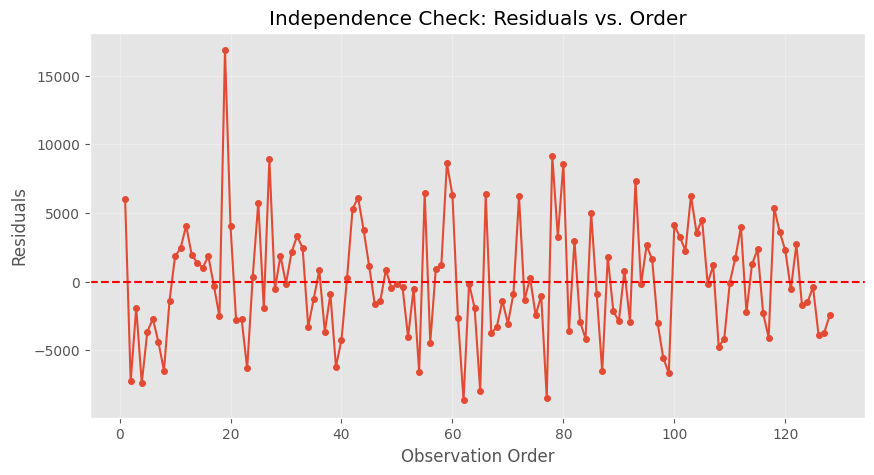

Durbin-Watson: 1.811


In [15]:
from statsmodels.stats.stattools import durbin_watson

residuals = np.asarray(model.resid)

plt.figure(figsize=(10, 5))

plt.plot(range(1, len(residuals) + 1),
         residuals,
         marker='o',
         markersize=4
         )

plt.axhline(0, color='red', linestyle='--')

plt.xlabel("Observation Order")
plt.ylabel("Residuals")
plt.title("Independence Check: Residuals vs. Order")
plt.grid(alpha=0.3)
plt.show()

print(f"Durbin-Watson: {durbin_watson(residuals):.3f}")


### 8.1 — Independence of Errors: Durbin–Watson Test

**Purpose:** Check whether consecutive regression errors are correlated (autocorrelation).

**What should we look for?**

- **Good:** Residuals fluctuate randomly around zero without a systematic pattern.
- **Potential problem:** Long runs, trends, or repeating patterns suggest autocorrelation.

**Durbin–Watson (DW) interpretation:**

| DW value | Interpretation |
|---|---|
| Near 2 | Little indication of first-order autocorrelation |
| Below 2 | Possible positive autocorrelation |
| Above 2 | Possible negative autocorrelation |

**Our observations:**

- Residuals fluctuate around zero without an obvious systematic pattern.
- One unusually large positive residual is visible.
- **Durbin–Watson = 1.811**, relatively close to 2.

**Conclusion:**

The graph and DW statistic show no strong indication of first-order autocorrelation in the displayed observation order.

**Important:** This conclusion is meaningful only if observations have a relevant order, such as time. For employees listed in arbitrary row order, independence must be assessed primarily from how the data were collected.

**Remember:** Durbin–Watson checks first-order autocorrelation; it does not prove complete independence of observations.

## Part D — Could unusual observations dominate the results?
### 9. Outliers, leverage and Cook's distance
**Purpose:** Detect large errors (studentized residuals), unusual Age values (leverage) and records whose omission may alter the fit (Cook's D).

**Screening only:** |studentized| > 3; leverage > 2p/n; Cook's D > 4/n. Investigate validity and sensitivity; do not delete observations automatically.

In [16]:
inf=model.get_influence()

p=int(model.df_model+1)
nobs=int(model.nobs)

influence_table=data.copy()

influence_table['Predicted']=model.fittedvalues
influence_table['Residual']=model.resid
influence_table['Studentized_Residual']=inf.resid_studentized_external
influence_table['Leverage']=inf.hat_matrix_diag
influence_table['Cooks_D']=inf.cooks_distance[0]
influence_table.head(2)

,Age,Salary,Predicted,Residual,Studentized_Residual,Leverage,Cooks_D
0,58.0,74862.0,68868.070761,5993.929239,1.434371,0.025160,0.026329
1,56.0,60652.0,67918.304534,-7266.304534,-1.742197,0.021423,0.032695


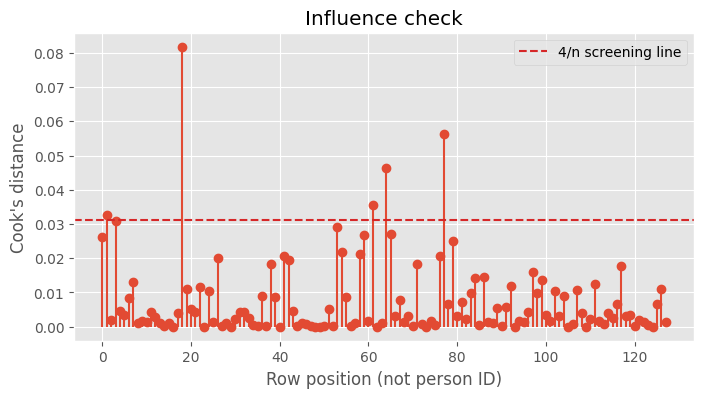

In [17]:
fig,ax=plt.subplots(figsize=(8,4))

ax.stem(np.arange(nobs),
        influence_table['Cooks_D'].values,basefmt=' '
        )

ax.axhline(4/nobs,
           color='tab:red',
           ls='--',
           label='4/n screening line'
           )

ax.set(xlabel='Row position (not person ID)',
       ylabel="Cook's distance",
       title='Influence check')

ax.legend()
plt.show()

### 9.1 — Outliers and Influence: Cook's Distance

**Purpose:** Identify observations that may strongly influence regression coefficients.

**Understanding the graph:**
- **Red dots and vertical lines:** Cook's Distance for each observation.
- **Red dashed line:** Screening threshold (4/n = 0.03125).

**What should we look for?**

- **Good:** Most observations have low Cook's Distance.
- **Potential concern:** Observations above the dashed line may have a strong influence on regression estimates.
- **Important:** The threshold is a screening guideline, not a formal statistical test.

**Our observations:**

- Most observations have Cook's Distance close to zero.
- Several observations exceed the threshold of 0.03125.
- The largest Cook's Distance is approximately 0.082.
- A few other observations have values around 0.047 and 0.056.

**Conclusion:**

Most observations show limited individual influence, but several are potentially influential. These observations should be investigated to determine whether they substantially affect the regression coefficients.

**Recommended action:** Compare regression estimates with and without the flagged observations as a sensitivity analysis.

**Remember:** An influential observation is not necessarily an error. Never remove valid observations simply because Cook's Distance exceeds a screening threshold.

## Part E — Does the model predict well?
### 10. Five-fold cross-validation vs a mean-salary baseline
**Purpose:** Estimate prediction error on held-out observations.

**Good:** Lower MAE and RMSE, higher out-of-fold R² than the simple baseline. Random folds are appropriate only when observations are genuinely exchangeable; grouped or time-based data require suitable splits.

In [18]:

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


X = data[['Age']]
y = data['Salary']

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Compare regression with baseline
models = {
    'Age-only Regression': LinearRegression(),
    'Mean Salary Baseline': DummyRegressor()
}

results = []

for name, model_cv in models.items():
    pred = cross_val_predict(model_cv, X, y, cv=cv)

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y, pred),
        'RMSE': np.sqrt(mean_squared_error(y, pred)),
        'CV_R²': r2_score(y, pred)
    })

display(pd.DataFrame(results).round(3))


,Model,MAE,RMSE,CV_R²
0,Age-only Regression,3426.862,4355.138,0.612
1,Mean Salary Baseline,5935.241,7054.317,-0.017


### 10.1 — Predictive Validation: 5-Fold Cross-Validation

**Purpose:** Check how accurately our regression model predicts Salary for new observations.

**How does it work?**

The data are divided into 5 groups. The model is trained on 4 groups and tested on the remaining group. This process repeats 5 times.

**What should we look for?**

| Measure | Good result | Poor result |
|---|---|---|
| MAE | Lower | Higher |
| RMSE | Lower | Higher |
| CV R² | Higher | Low or negative |

**Our results:**

| Measure | Age-only regression | Mean-salary baseline |
|---|---:|---:|
| MAE | 3,426.86 | 5,935.24 |
| RMSE | 4,355.14 | 7,054.32 |
| CV R² | 0.612 | −0.017 |

**Our observations:**

- The Age-only regression has substantially lower prediction errors than the baseline.
- MAE = 3,426.86 means predictions differ from actual salaries by approximately 3,427 salary units on average.
- CV R² = 0.612 indicates useful predictive performance.
- The regression performs better than simply predicting the average salary.

**Conclusion:**

The Age-only regression demonstrates useful predictive ability for held-out observations and substantially outperforms the mean-salary baseline.

**Remember:** Good cross-validation results do not guarantee accurate predictions for every individual or prove that Age causes Salary to increase. Results also depend on whether the validation method represents how the model will be used.

### 11. Confidence interval versus prediction interval

**Purpose:** Understand the uncertainty when predicting average Salary versus an individual employee's Salary.

**What is the difference?**

- **Confidence Interval (CI):** Estimates the range of uncertainty for `the average salary `at a given age.
- **Prediction Interval (PI):** Estimates the range of uncertainty for `one individual's salary` at that age.

**What should we look for?**

- **Good:** Narrower intervals indicate greater precision.
- **Potential concern:** Wider intervals indicate greater uncertainty.
- **Important:** Prediction intervals are wider because individual salaries vary around the average.


In [19]:
# Select age
age = data['Age'].median()

# Predict salary with 95% intervals
new_data = pd.DataFrame({'const': [1], 'Age': [age]})
display(new_data)

pred = model.get_prediction(new_data).summary_frame(alpha=0.05)

# Display results
print(f"Age: {age}")
result = pd.DataFrame({
    'Measure': ['Predicted Salary', '95% Confidence Interval',
                '95% Prediction Interval'],
    'Result': [
        f"{pred['mean'].iloc[0]:,.2f}",
        f"{pred['mean_ci_lower'].iloc[0]:,.2f} – {pred['mean_ci_upper'].iloc[0]:,.2f}",
        f"{pred['obs_ci_lower'].iloc[0]:,.2f} – {pred['obs_ci_upper'].iloc[0]:,.2f}"
    ]
})

display(result)

,const,Age
0,1,41.0


Age: 41.0


,Measure,Result
0,Predicted Salary,"60,795.06"
1,95% Confidence Interval,"60,050.95 – 61,539.17"
2,95% Prediction Interval,"52,351.40 – 69,238.71"


### 11.1 — Confidence Interval vs. Prediction Interval: Interpretation

**Our results (Age = 41):**

| Measure | Salary |
|---|---:|
| Predicted average salary | 60,795.06 |
| 95% Confidence Interval | 60,050.95 – 61,539.17 |
| 95% Prediction Interval | 52,351.40 – 69,238.71 |

**Our observations:**

- The confidence interval is narrow, indicating a relatively precise estimate of average salary.
- The prediction interval is much wider, indicating greater uncertainty when predicting an individual's salary.

**Conclusion:**

At age 41, the model predicts an average salary of approximately 60,795. We can estimate the average salary more precisely than the salary of an individual employee.

**Remember:** A 95% confidence interval concerns the population mean, while a 95% prediction interval concerns a new individual observation. Both depend on appropriate model assumptions.

## Part F — Final model evaluation
### 12. One-screen diagnostic report
**Purpose:** Bring the statistical checks together. **Read them in context**: p-values are not pass/fail certificates; Cook's D and leverage are screening statistics. Interpret DW only when order is meaningful.

In [20]:
from statsmodels.stats.diagnostic import linear_reset, het_breuschpagan, het_white, normal_ad
from statsmodels.stats.stattools import jarque_bera, omni_normtest, durbin_watson

resid = np.asarray(model.resid)
inf = model.get_influence()
n, p = int(model.nobs), len(model.params)

# Formal tests: look at p-values
checks = [
    ('Model form', 'RESET', float(linear_reset(model, power=2, use_f=True).pvalue)),
    ('Variance', 'Breusch–Pagan', het_breuschpagan(resid, model.model.exog)[1]),
    ('Variance', 'White', het_white(resid, model.model.exog)[1]),
    ('Normality', 'Jarque–Bera', jarque_bera(resid)[1]),
    ('Normality', 'Omnibus', omni_normtest(resid)[1]),
    ('Normality', 'Anderson–Darling', normal_ad(resid)[1]),
]
rows = [{'Area': a, 'Diagnostic': b, 'Value': round(float(v), 4),
         'Guide': 'p < 0.05',
         'Reading': 'Investigate' if v < .05 else 'Not rejected at 5%'}
        for a, b, v in checks]

# Screening guides: these are NOT p-values
for area, test, value, limit in [
    ('Influence', 'Max Cook D', np.max(inf.cooks_distance[0]), 4/n),
    ('Outliers', 'Max |Studentized|', np.max(np.abs(inf.resid_studentized_external)), 3),
    ('Leverage', 'Max leverage', np.max(inf.hat_matrix_diag), 2*p/n),
]:
    rows.append({'Area': area, 'Diagnostic': test, 'Value': round(float(value), 4),
                 'Guide': f'> {limit:.4f}',
                 'Reading': 'Investigate' if value > limit else 'Below screening rule'})
rows.append({'Area': 'Ordered errors', 'Diagnostic': 'Durbin–Watson',
             'Value': round(float(durbin_watson(resid)), 4), 'Guide': 'Near 2',
             'Reading': 'Only if row order is meaningful'})

report = pd.DataFrame(rows)
display(report)
print('A nonsignificant p-value does not prove an assumption.')
print('Also inspect plots, data quality, study design, and held-out prediction errors.')

,Area,Diagnostic,Value,Guide,Reading
0,Model form,RESET,0.7180,p < 0.05,Not rejected at 5%
1,Variance,Breusch–Pagan,0.0695,p < 0.05,Not rejected at 5%
2,Variance,White,0.1744,p < 0.05,Not rejected at 5%
3,Normality,Jarque–Bera,0.0026,p < 0.05,Investigate
4,Normality,Omnibus,0.0048,p < 0.05,Investigate
5,Normality,Anderson–Darling,0.3214,p < 0.05,Not rejected at 5%
6,Influence,Max Cook D,0.0818,> 0.0312,Investigate
7,Outliers,Max |Studentized|,4.2452,> 3.0000,Investigate
8,Leverage,Max leverage,0.0272,> 0.0312,Below screening rule
9,Ordered errors,Durbin–Watson,1.8107,Near 2,Only if row order is meaningful


A nonsignificant p-value does not prove an assumption.
Also inspect plots, data quality, study design, and held-out prediction errors.


### 13. Final conclusions — what can we responsibly say?

- **Relationship:** Explain the sign and magnitude of Age's coefficient and uncertainty.
- **Shape:** Compare scatterplot, LOWESS, quadratic test, RESET, and lack-of-fit.
- **Residuals:** Examine equal variance, normality, dependence and unusual observations.
- **Prediction:** Compare held-out MAE/RMSE with a simple baseline; report uncertainty intervals.
- **Design:** Ask whether salary was consistently measured, samples are representative, and age is confounded with occupation, education or experience.

**Bottom line:** A useful regression needs an appropriate purpose, plausible assumptions, stable coefficients and acceptable predictive performance. **A high R² alone is not enough.**

**Class discussion:** Can a model predict well even if residual normality is rejected? Can a significant Age coefficient prove age causes salary changes?

---
## Optional applications (not required for validating the Age-only model)
### A. Multicollinearity — only when using multiple predictors
**Purpose:** In multiple regression, VIF flags overlap among predictors. With Age alone, VIF = 1 by definition. The next code runs only if additional *real* recorded numeric predictors exist. **Do not invent new columns.**

In [21]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Use additional numerical predictors only if present in the original file
extra = [c for c in ['Weight', 'JoinYear', 'Experience'] if c in df.columns]
predictors = ['Age'] + extra
X_multi = df[predictors].apply(pd.to_numeric, errors='coerce').dropna()

if len(predictors) < 2 or len(X_multi) <= len(predictors) + 1:
    print('Age-only regression: VIF(Age) = 1. No multicollinearity test needed.')
    vif = pd.Series(dtype=float)
else:
    X_vif = sm.add_constant(X_multi, has_constant='add')
    vif = pd.Series({col: variance_inflation_factor(X_vif.values, i)
                     for i, col in enumerate(X_vif.columns) if col != 'const'}, name='VIF')
    display(vif.round(3).to_frame())

,VIF
Age,1.033
Weight,1.009
JoinYear,1.041


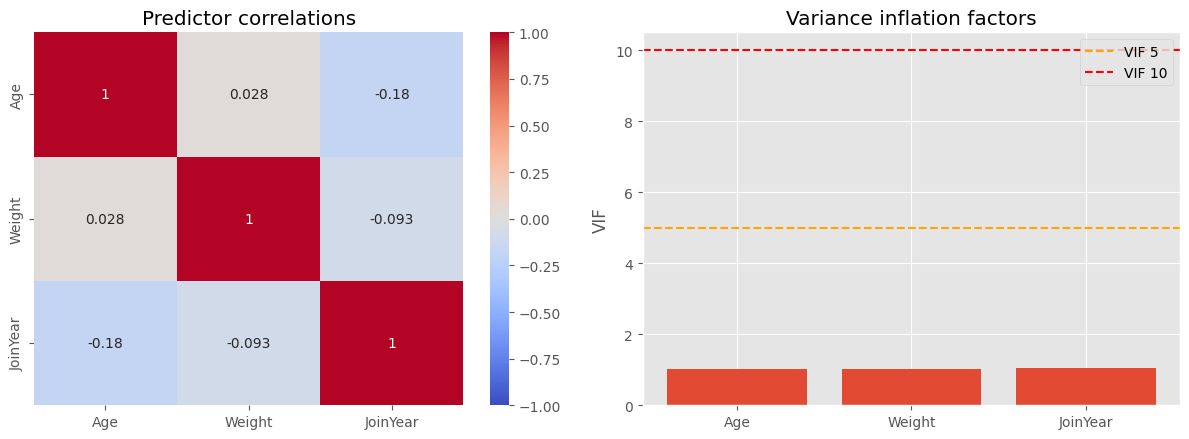

In [22]:
# Two charts, only if two or more real numerical predictors were found
if len(vif) > 1:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.heatmap(X_multi.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=ax[0])
    ax[0].set_title('Predictor correlations')

    ax[1].bar(vif.index, vif.values)
    ax[1].axhline(5, ls='--', color='orange', label='VIF 5')
    ax[1].axhline(10, ls='--', color='red', label='VIF 10')
    ax[1].set_title('Variance inflation factors')
    ax[1].set_ylabel('VIF')
    ax[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print('Not enough recorded predictors for meaningful correlation/VIF charts.')

### 13.1 — Multicollinearity: Correlation Heatmap and VIF

**Purpose:** Check whether explanatory variables are strongly related to each other, which can make regression coefficients unstable.

**What should we look for?**

| Diagnostic | Good | Potential problem |
|---|---|---|
| Correlation heatmap | Correlations near 0 | Correlations near +1 or −1 |
| VIF | Near 1; generally below 5 | Above 5, especially above 10 |

*VIF thresholds are screening guidelines, not strict statistical rules.*

**Our results:**

| Variable | VIF |
|---|---:|
| Age | 1.033 |
| Weight | 1.009 |
| JoinYear | 1.041 |

**Our observations:**

- Age and Weight have almost no linear correlation (0.028).
- Age and JoinYear have a weak negative correlation (−0.18).
- Weight and JoinYear have a weak negative correlation (−0.093).
- All VIF values are close to 1 and well below 5.

**Conclusion:**

The correlation heatmap and VIF results show no meaningful multicollinearity among Age, Weight, and JoinYear.

**Remember:** High multicollinearity may increase standard errors and make individual coefficients unstable, even when predictions are reasonably accurate.

### B. Response optimizer — illustrative, not a model-quality test
**Purpose:** Find ages with the highest/lowest *predicted* salary or closest to a target, within the observed range. Age cannot be controlled in practice, so this is only a classroom demonstration. A linear model generally selects boundary ages for Minimize/Maximize.

In [23]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import ipywidgets as widgets
from IPython.display import display

# Candidate ages within observed range
ages = np.arange(int(data['Age'].min()),
                 int(data['Age'].max()) + 1)

candidates = pd.DataFrame({'Age': ages})
candidates['Predicted Salary'] = model.predict(
    sm.add_constant(candidates, has_constant='add')
)

# Interactive optimizer
def optimize(objective, target_salary):

    df = candidates.copy()

    if objective == 'Maximize':
        top5 = df.nlargest(5, 'Predicted Salary')

    elif objective == 'Minimize':
        top5 = df.nsmallest(5, 'Predicted Salary')

    else:
        df['Distance from Target'] = abs(
            df['Predicted Salary'] - target_salary
        )
        top5 = df.nsmallest(5, 'Distance from Target')

    top5 = top5.copy()
    top5.insert(0, 'Rank', range(1, len(top5) + 1))

    display(top5.round(2))

    # Plot
    plt.figure(figsize=(10, 5))

    plt.plot(df['Age'], df['Predicted Salary'],
             color='steelblue', label='Regression Prediction')

    plt.scatter(top5['Age'], top5['Predicted Salary'],
                color='red', s=90, zorder=3,
                label='Top 5 Solutions')

    if objective == 'Target':
        plt.axhline(target_salary, color='green',
                    linestyle='--', label='Target Salary')

    plt.xlabel('Age')
    plt.ylabel('Predicted Salary')
    plt.title(f'Response Optimizer — {objective}')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

# Dropdown and target input
widgets.interact(
    optimize,
    objective=widgets.Dropdown(
        options=['Maximize', 'Minimize', 'Target'],
        value='Maximize',
        description='Objective:'
    ),
    target_salary=widgets.FloatText(
        value=60700,
        description='Target Salary:'
    )
)


interactive(children=(Dropdown(description='Objective:', options=('Maximize', 'Minimize', 'Target'), value='Ma…

<function __main__.optimize(objective, target_salary)>